In [21]:
# A. Building the Base Model: Infection Dynamics in a Population
# (i) Environment and initial conditions

import random

gridSize = 20
totalAgent = 200
initiallyInfected = 5

def initialAgents(seed=50):
  randomGenerator = random.Random(seed)

  states = (
      ["S"] * (totalAgent - initiallyInfected) #195 healthy
      + ["I"] * initiallyInfected #5 infected
  )

  randomGenerator.shuffle(states)
  agents = []
  for i in range(totalAgent):
    person = {
        "id": i,
        "x": randomGenerator.randrange(gridSize),
        "y": randomGenerator.randrange(gridSize),
        "state": states[i]
    }
    agents.append(person)
  return agents

agents = initialAgents()
print("Total agents:", len(agents))


Total agents: 200


In [22]:
# (ii) Agent behaviors

# function for movement
def moveAgents(agents, randomGenerator):
  for agent in agents:
    moves = [(0,0), (1,0), (-1,0), (0,1), (0,-1)] # No move, right, left, down, up

    validMoves = [] # only inside the grid
    for dx, dy in moves:
      newX = agent["x"] + dx # dx means change in x coordinate
      newY = agent["y"] + dy # dy means change in y coordinate

      if 0 <= newX < gridSize and 0 <= newY < gridSize:
        validMoves.append((dx, dy))

    dx, dy = randomGenerator.choice(validMoves) # choosing the random move
    agent["x"] +=dx
    agent["y"] +=dy



# function for infection
def infectAgents(agents, p, randomGenerator):
  infectedPositions = set() # finding infected ones
  for agent in agents:
    if agent["state"]=="I":
      infectedPositions.add((agent["x"], agent["y"]))

  for agent in agents: # checking susceptiible ones
    if agent["state"]=="S":
      position = (agent["x"], agent["y"])
      if position in infectedPositions:
        if randomGenerator.random()<p:
          agent["state"]="I"



# function for recovery
def recoverAgents(agents, q, randomGenerator, alreadyInfected): # alreadyInfected means who are already infected at the start
  for agent in agents:
    if agent["id"] in alreadyInfected:
      if randomGenerator.random()<q:
        agent["state"] = "R"


# lets combine all three
def simulation(agents, p, q, randomGenerator):
  alreadyInfected = {
      agent["id"]
      for agent in agents
      if agent["state"]=="I"

  }
  moveAgents(agents, randomGenerator) # move all agents
  infectAgents(agents, p, randomGenerator) # infection
  recoverAgents(agents, q, randomGenerator, alreadyInfected) # recover already infected ones



randomGenerator = random.Random(51)
p=0.3
q=0.02

simulation(agents, p, q, randomGenerator)
# Check results
print("Susceptible:", sum(a["state"] == "S" for a in agents))
print("Infected:", sum(a["state"] == "I" for a in agents))
print("Recovered:", sum(a["state"] == "R" for a in agents))


Susceptible: 195
Infected: 5
Recovered: 0


final susceptible = 0
final infected = 1
final recovered = 199


peak infected agents = 82
peak time = 92
total infected agents = 200


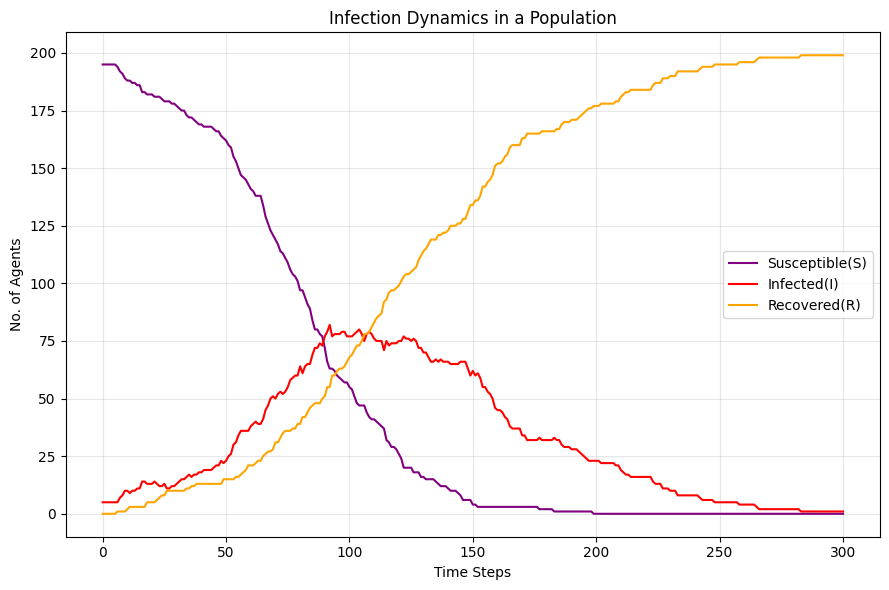

In [23]:
# (iii)  Simulation


import matplotlib
agents = initialAgents(seed=50)
randomGenerator = random.Random(51)

p=0.3 # given
q=0.02
timeSteps=300
susceptibleOnes=[]
infectedOnes=[]
recoveredOnes=[]
for step in range(timeSteps+1):
  # counting agents in all states
  s = sum(a["state"]=="S" for a in agents)
  i = sum(a["state"]=="I" for a in agents)
  r = sum(a["state"]=="R" for a in agents)
  susceptibleOnes.append(s)
  infectedOnes.append(i)
  recoveredOnes.append(r)
  if step<timeSteps: # next step
    simulation(agents, p, q, randomGenerator)

print("final susceptible =", susceptibleOnes[-1])
print("final infected =", infectedOnes[-1])
print("final recovered =", recoveredOnes[-1])
print("\n")

peakInfectedAgents = max(infectedOnes) # infection peak
peakTime = infectedOnes.index(peakInfectedAgents)
totalInfected = totalAgent - susceptibleOnes[-1] # total infected agents
print("peak infected agents =", peakInfectedAgents)
print("peak time =", peakTime)
print("total infected agents =", totalInfected)

# Plotting S, I, R with time steps
matplotlib.pyplot.figure(figsize=(9,6))
matplotlib.pyplot.plot(susceptibleOnes, label="Susceptible(S)", color="purple")
matplotlib.pyplot.plot(infectedOnes, label="Infected(I)", color="red")
matplotlib.pyplot.plot(recoveredOnes, label="Recovered(R)", color="orange")
matplotlib.pyplot.xlabel("Time Steps")
matplotlib.pyplot.ylabel("No. of Agents")
matplotlib.pyplot.title("Infection Dynamics in a Population")
matplotlib.pyplot.legend()
matplotlib.pyplot.grid(True, alpha=0.3)
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.savefig("partA.png")
matplotlib.pyplot.show()


My observations -
* Initially there were 5 infected and it reached the peak 82 at step 92(peak time).
* All 200 agents got infected.
* At step 300, 199 agents got recovered and 1 was still infected.



p = 0.15 and q = 0.02
Avg. Peak = 52.55
Peak Std = 19.087888830355233
Avg. Peak Time = 114.0
Peak Time Std = 48.008332610079265
Avg. Total Infected = 165.65
Total Infected Std = 52.94740314689664
Peak Range = 5 to 76
Total Early Die-Outs = 2


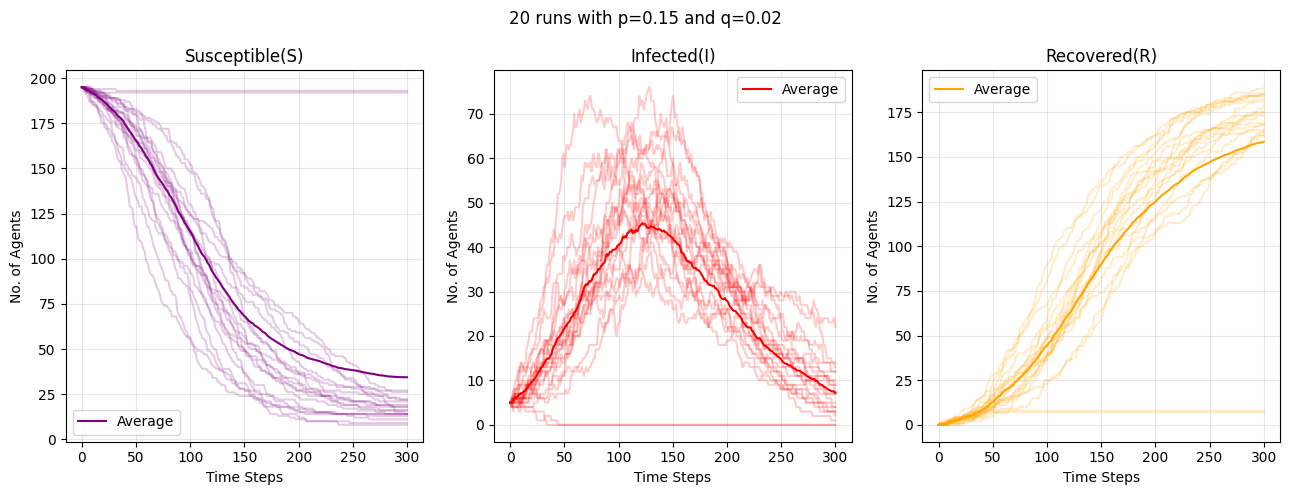



p = 0.15 and q = 0.04
Avg. Peak = 16.35
Peak Std = 7.812009984632636
Avg. Peak Time = 61.75
Peak Time Std = 38.46930594642955
Avg. Total Infected = 73.95
Total Infected Std = 45.10263296083722
Peak Range = 5 to 30
Total Early Die-Outs = 2


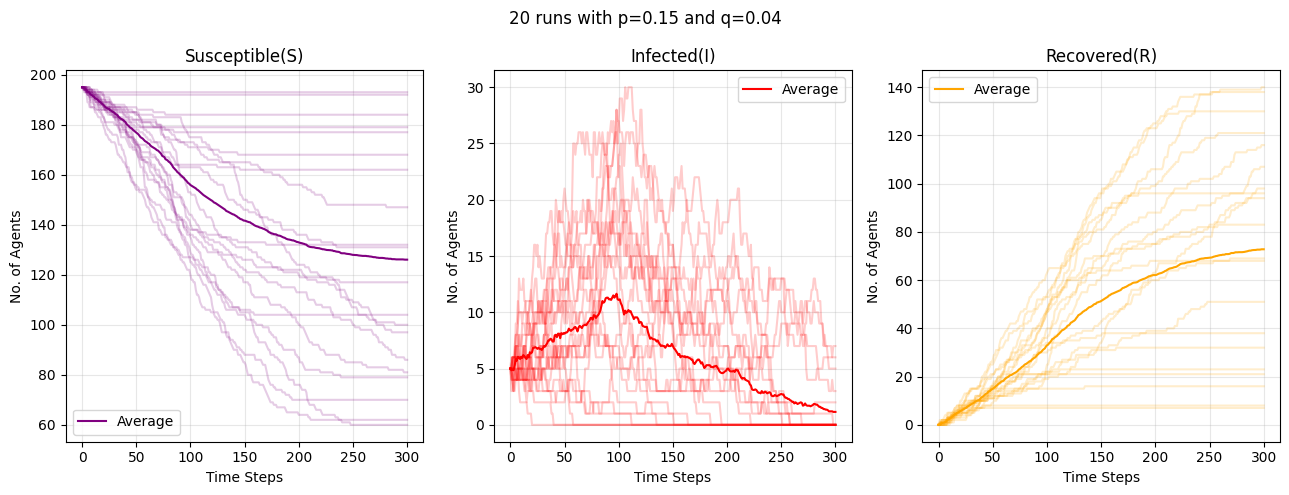



p = 0.3 and q = 0.02
Avg. Peak = 91.85
Peak Std = 13.84295849881809
Avg. Peak Time = 82.3
Peak Time Std = 21.48976500569515
Avg. Total Infected = 198.7
Total Infected Std = 1.1874342087037917
Peak Range = 63 to 116
Total Early Die-Outs = 0


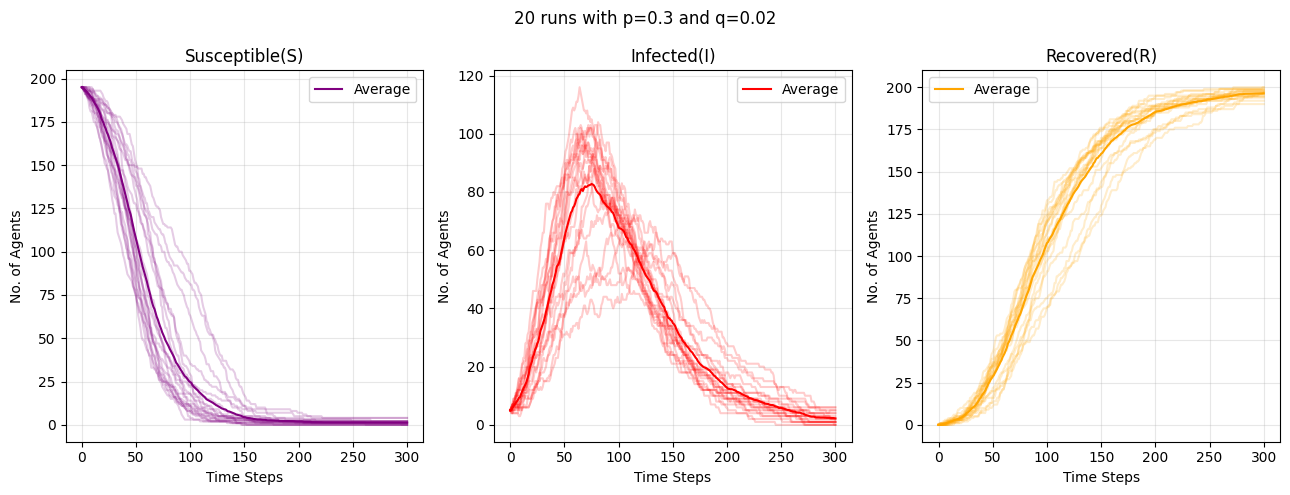



p = 0.3 and q = 0.04
Avg. Peak = 49.5
Peak Std = 11.298229949863828
Avg. Peak Time = 70.05
Peak Time Std = 21.174217813180253
Avg. Total Infected = 178.7
Total Infected Std = 8.764131445842194
Peak Range = 32 to 79
Total Early Die-Outs = 0


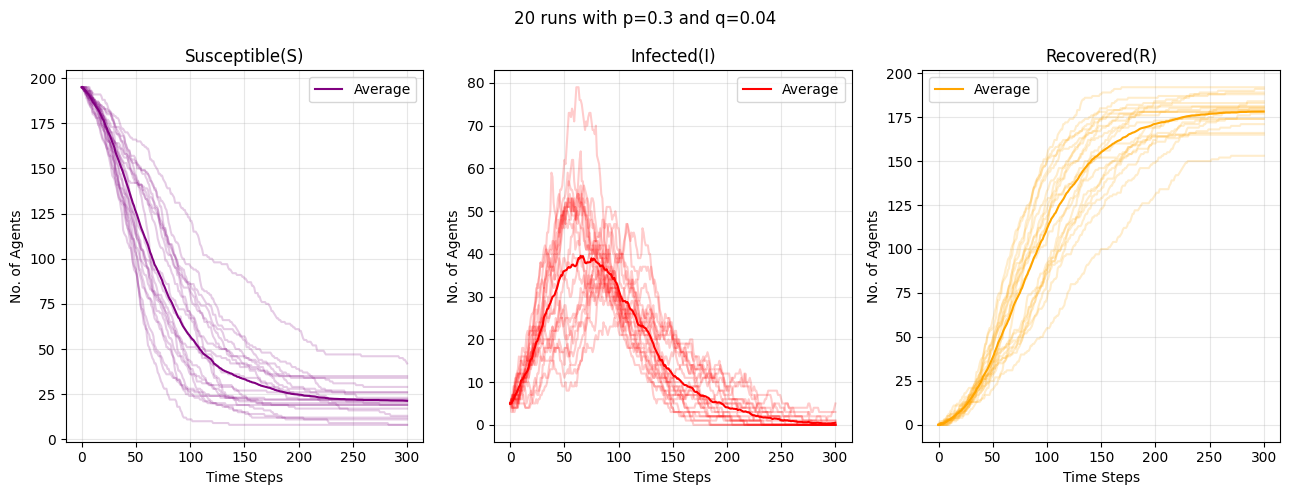

In [24]:
# (iv) Sensitivity analysis

import numpy
import matplotlib

# Exact Same logic that we used in (iii) simulation
def runSimulation(p, q, seed):
  agents = initialAgents(seed)
  randomGenerator = random.Random(seed+1000)
  result = []

  for step in range(301):
    count = [
        sum(a["state"]=="S" for a in agents),
        sum(a["state"]=="I" for a in agents),
        sum(a["state"]=="R" for a in agents)
    ]
    result.append(count)

    if step<300: # next step
      simulation(agents,p,q,randomGenerator)
  return numpy.array(result)

# p-q combinations -
for p in [0.15,0.30]:
  for q in [0.02,0.04]:
    runs = numpy.array([
        runSimulation(p,q, 50+run)
        for run in range(20)
    ])

    infected = runs[:,:,1]
    peak = infected.max(axis=1)
    peakTimes = infected.argmax(axis=1)
    totalInfected = totalAgent -runs[:, -1, 0]
    early = numpy.sum(infected[:, 50]==0) # early die-out - no infected agents by step 50

    print("\n")
    print(f"p = {p} and q = {q}")
    print(f"Avg. Peak = {peak.mean()}")
    print(f"Peak Std = {peak.std()}")
    print(f"Avg. Peak Time = {peakTimes.mean()}")
    print(f"Peak Time Std = {peakTimes.std()}")
    print(f"Avg. Total Infected = {totalInfected.mean()}")
    print(f"Total Infected Std = {totalInfected.std()}")
    print(f"Peak Range = {peak.min()} to {peak.max()}")
    print(f"Total Early Die-Outs = {early}")

    # Plotting all runs and average
    fig, axes = matplotlib.pyplot.subplots(1,3, figsize=(13,5))
    for i, (name, color) in enumerate([
        ("Susceptible(S)", "purple"),
        ("Infected(I)", "red"),
        ("Recovered(R)", "orange")]):
        data = runs[:,:,i]
        axes[i].plot(data.T, color=color, alpha=0.2)
        axes[i].plot(data.mean(axis=0), color=color, label="Average")
        axes[i].set_xlabel("Time Steps")
        axes[i].set_ylabel("No. of Agents")
        axes[i].set_title(name)
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)

    fig.suptitle(f"20 runs with p={p} and q={q}")
    matplotlib.pyplot.savefig(f"partA_{p}_{q}.png")
    matplotlib.pyplot.tight_layout()
    matplotlib.pyplot.show()




My observations (I tried lots of other p-q combinations as well)-
* If we take high p, it is increasing the infection prak and total no. of infections.
* If we take high q, it is decreasing the infection peak and total infections.
* The individual runs gave different results because of random movenent, infection and recovery.
* The average curve looks similar to the SIR model we studied in the lecture.  
* We got 2 early die outs both times when p was 0.15 but we there is no early die outs when p is 0.30



In [25]:
# B. Extending the Model: Social Distancing and Interventions
# (i) Introduce social distancing - Reduced Movement

def moveAgentsPartB(agents, randomGenerator, m=1.0): # this is a bit different function from moveAgent because here staying is controlled by variable m unlike other where staying was one of the choice.
  allMoves = [(0,0), (1,0), (-1,0), (0,1), (0,-1)]
  for agent in agents:
    if randomGenerator.random() < m: # this is important here - if this condition is true only then the agent moves otherwise it stays.
      validMoves = []
      for dx, dy in allMoves:
        newX = agent["x"] + dx
        newY = agent["y"] + dy
        if 0 <= newX < gridSize and 0 <= newY < gridSize:
          validMoves.append((dx,dy))

      dx, dy = randomGenerator.choice(validMoves)
      agent["x"] += dx
      agent["y"] += dy



# This is exactly same simulation function as part A with same infectAgents and recoverAgents, the only difference is m and simulationPartB
def simulationPartB(agents,p,q,randomGenerator,m=1.0, avoidance=False):
  alreadyInfected = {
      agent["id"]
      for agent in agents
      if agent["state"]=="I"
  }
  # choosing the path
  if avoidance:
    moveAgentsAvoidance(agents, randomGenerator)
  else:
    moveAgentsPartB(agents, randomGenerator, m)
  # same infection and recovery function for both
  infectAgents(agents, p, randomGenerator)
  recoverAgents(agents, q, randomGenerator, alreadyInfected)

agents = initialAgents(seed=50)
randomGenerator = random.Random(51)

before = [(a["x"], a["y"]) for a in agents]
moveAgentsPartB(agents, randomGenerator, m=0.3)
moved = sum(
    (a["x"], a["y"]) != old
    for a, old in zip(agents, before)
)
assert all(
    0<=a["x"]<gridSize and 0<=a["y"]<gridSize
    for a in agents
)



# Avoidance fucntions very similar to moveAgentsPartB function
def moveAgentsAvoidance(agents, randomGenerator):
  infectedPositions = {
      (agent["x"], agent["y"])
      for agent in agents
      if agent["state"]=="I"
  }
  allMoves = [(0,0), (1,0), (-1,0), (0,1), (0,-1)]
  for agent in agents:
    validMoves = []
    for dx, dy in allMoves:
      newX = agent["x"] + dx
      newY = agent["y"] + dy
      if 0 <= newX < gridSize and 0 <= newY < gridSize:
        if agent["state"] !="S" or (newX, newY) not in infectedPositions:
          validMoves.append((dx,dy))
    if not validMoves:
      validMoves = [(0,0)] # need to stay if there is no valid move

    dx, dy = randomGenerator.choice(validMoves) # choose the move
    agent["x"] += dx
    agent["y"] += dy




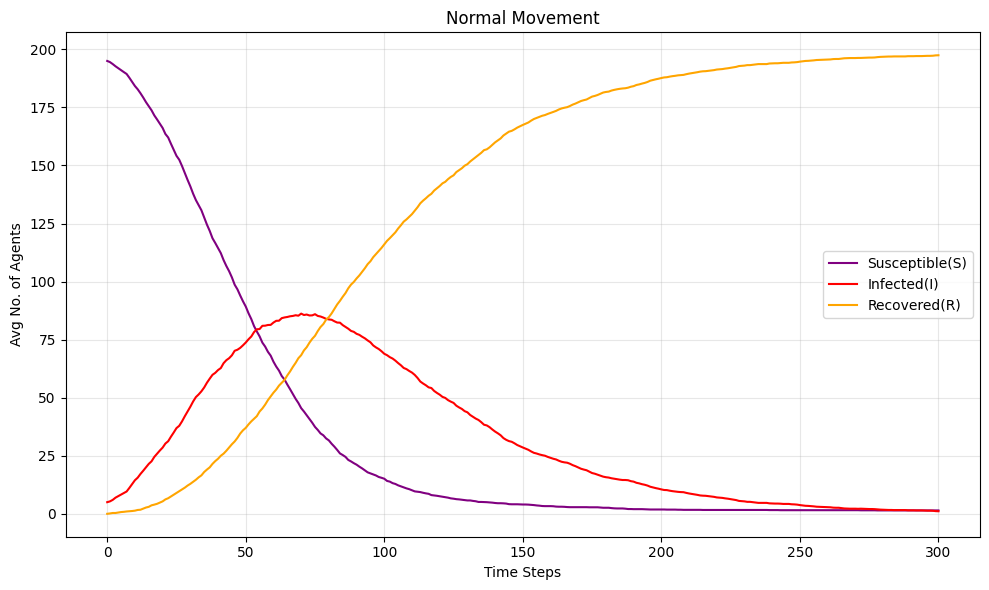

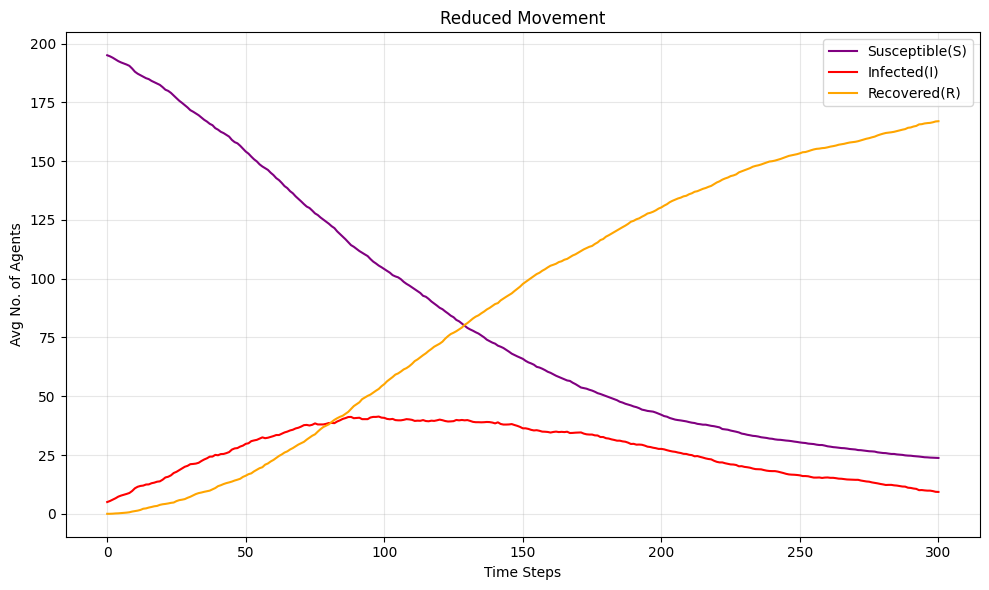

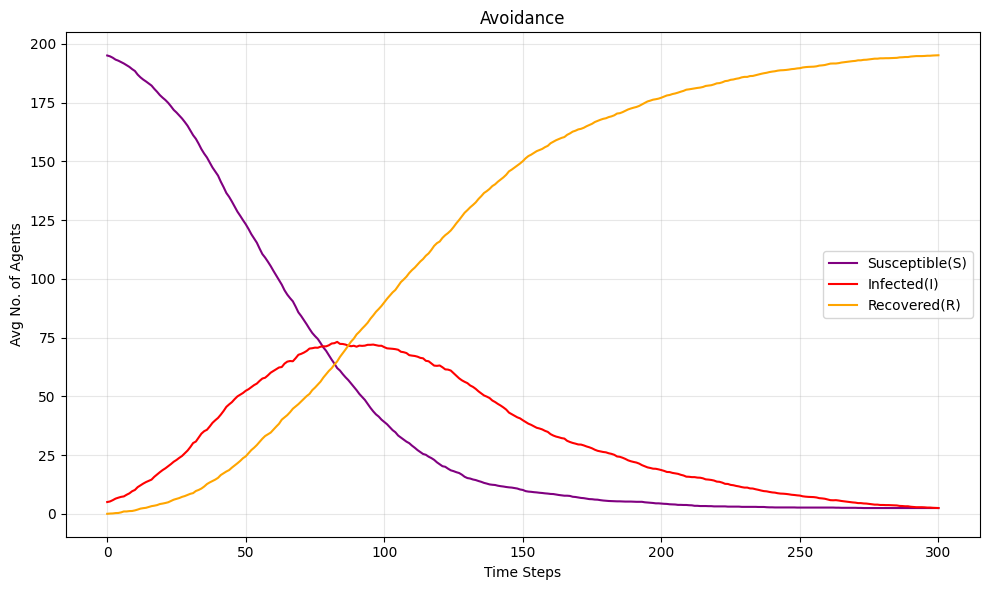

In [26]:
# Part B(i) Experiments -

import numpy
import matplotlib.pyplot as plt

# simulation for 300 steps
def runPartB(seed, m=1.0, avoidance= False):
  agents = initialAgents(seed)
  randomGenerator = random.Random(seed+1000)
  results = []
  for step in range(301):
    count = [
        sum(a["state"]=="S" for a in agents),
        sum(a["state"]=="I" for a in agents),
        sum(a["state"]=="R" for a in agents)
    ]
    results.append(count)

    if step < 300:
      simulationPartB(agents, 0.3, 0.02, randomGenerator, m, avoidance)
  return numpy.array(results)

methods = [
    ("Normal Movement", 1.0, False),
    ("Reduced Movement", 0.3, False),
    ("Avoidance", 1.0, True)
]

resultsPartB = {}
for name, m, avoidance in methods:
  runs = numpy.array([
      runPartB(50+run, m, avoidance)
      for run in range(20)
  ])
  resultsPartB[name] = runs
  average = runs.mean(axis=0)
  plt.figure(figsize=(10,6))
  for i, (state, color) in enumerate([
      ("Susceptible(S)", "purple"),
      ("Infected(I)", "red"),
      ("Recovered(R)", "orange")
  ]):
    plt.plot(average[:,i], label=state, color=color)
  plt.xlabel("Time Steps")
  plt.ylabel("Avg No. of Agents")
  plt.title(name)
  plt.legend()
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.savefig(f"partB_{name}.png")
  plt.show()


My observations -
*   Normal Movement - Infection is spreading quickly and reached a high peak.
*   Reduced Movement - Less no. of agents are infected and it is slow as well in terms of spreading.
*   Avoidance - Infection peak is almost similar to normal movement but a bit low.
*   Reduced movement looks better than avoidance and normal movement in this simulation result.
* As we can see that m affects the infection peak alot more than other factors. When m is low, we got very less agents infected.
* And the healthcare systems can feel overwhelmed if the peak infection become high that means more no. patients at the same time in the real world setting.

In [27]:
# Part B(ii) Compare the results -

for name, runs in resultsPartB.items():
  infected = runs[:,:,1]
  peak = infected.max(axis=1)
  peakTimes = infected.argmax(axis=1)
  totalInfected = totalAgent - runs[:, -1, 0]

  endTimes = [] # finding when infection reach 0
  for curve in infected:
    zeroSteps = numpy.where(curve==0)[0]
    if len(zeroSteps)>0:
      endTimes.append(zeroSteps[0])

  print("\n", name)
  print("Avg. Peak = ", peak.mean())
  print("Peak Std = ", peak.std())
  print("Avg. Peak Time = ", peakTimes.mean())
  print("Peak Time Std = ", peakTimes.std())
  print("Outbreaks ended =", len(endTimes), "out of 20")
  print("Avg. Total Infected = ", totalInfected.mean())
  print("Total Infected Std = ", totalInfected.std())

  if endTimes:
    print("Avg. End Time =", numpy.mean(endTimes))
  else:
    print("No one ended before 300 steps")



 Normal Movement
Avg. Peak =  95.05
Peak Std =  9.917030805639357
Avg. Peak Time =  71.1
Peak Time Std =  13.049521064008442
Outbreaks ended = 7 out of 20
Avg. Total Infected =  198.55
Total Infected Std =  1.116915395184434
Avg. End Time = 284.2857142857143

 Reduced Movement
Avg. Peak =  51.5
Peak Std =  9.102197536858887
Avg. Peak Time =  108.55
Peak Time Std =  37.98088334939039
Outbreaks ended = 0 out of 20
Avg. Total Infected =  176.25
Total Infected Std =  12.684143644724305
No one ended before 300 steps

 Avoidance
Avg. Peak =  87.05
Peak Std =  11.106191966646353
Avg. Peak Time =  88.95
Peak Time Std =  21.47201667286983
Outbreaks ended = 3 out of 20
Avg. Total Infected =  197.55
Total Infected Std =  1.8020821290940099
Avg. End Time = 269.3333333333333


Observations - (Interesting numbers)
* Normal Movement - Spreading quickly with avg peak of around 95.
* Reduced Movement - Peak dropped to 51.5 from 95 and occured later. It means reduced movement slow down the spread.
* Avoidance - Lower peak(around 87) than normal movement.
* Noarmal had around 199 infections and avoidance had almost same 198 but the reduced movement had 176 agents infected.
* Overall reduced movement is better at reducing and delaying the infection peak and avoidance made very less difference.
* 7 outbreaks in normal movement and 3 in avoidance. The average end time in normal movement is 284 steps and in avodance its 269 steps.
* Out of these three, reduced movement is best in lowering the infection peak and in real worlds it can help in putting less burden on the hospitals.



m = 0.1 
Avg. Peak = 16.0 
Avg. Peak Time = 61.15

m = 0.3 
Avg. Peak = 51.5 
Avg. Peak Time = 108.55

m = 0.6 
Avg. Peak = 79.8 
Avg. Peak Time = 86.2

m = 1.0 
Avg. Peak = 95.05 
Avg. Peak Time = 71.1


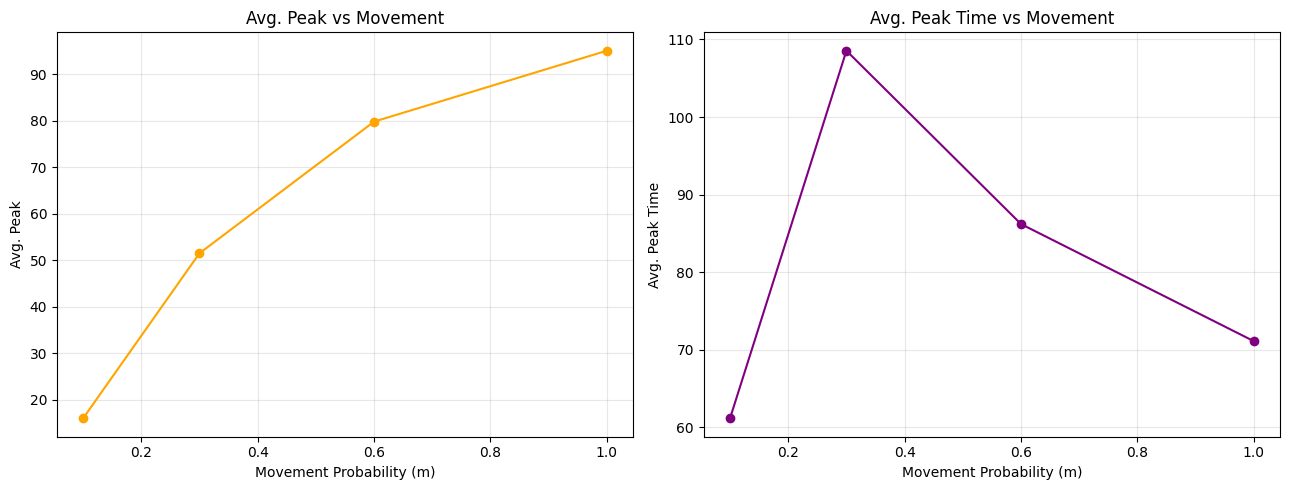

In [28]:
# Part B(iii) - Strength of distancing

mValues = [0.1, 0.3, 0.6, 1.0]
avgPeaks = []
avgPeakTimes = []

for m in mValues: # run 20 simulations for all 4 values of m
  runs = numpy.array([
      runPartB(50+run, m)
      for run in range(20)
  ])

  infected = runs[:,:,1]
  peak = infected.max(axis=1)
  peakTimes = infected.argmax(axis=1)
  avgPeaks.append(peak.mean())
  avgPeakTimes.append(peakTimes.mean())
  print("\nm =", m, "\nAvg. Peak =", peak.mean(), "\nAvg. Peak Time =", peakTimes.mean())

# Plotting results -
fig, axes = plt.subplots(1,2, figsize=(13,5))
# for Avg. Peaks vs m
axes[0].plot(mValues, avgPeaks, marker="o", color="orange")
axes[0].set_xlabel("Movement Probability (m)")
axes[0].set_ylabel("Avg. Peak")
axes[0].set_title("Avg. Peak vs Movement")
axes[0].grid(True, alpha=0.3)
# for Avg. Peak Time vs m
axes[1].plot(mValues, avgPeakTimes, marker="o", color="purple")
axes[1].set_xlabel("Movement Probability (m)")
axes[1].set_ylabel("Avg. Peak Time")
axes[1].set_title("Avg. Peak Time vs Movement")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig("partB_strength_of_distancing.png")
plt.show()



My observation -
* m=0.1 => Lowest avg. infection peak with 16
* m=0.3 => Peak increased to 51.5 from 16
* m=0.6 => Peak increased to 79.8 now
* m=1.0 => Highest Peak around 95
* Overall if we maintain strict social distancing(low m), it reduce the infection peak.
* Interesting thing is reducing the m does not diretly mean delaying the peak.


**Bonus (i)**

 I got inspired by the reference YouTube video of simuating the pendemic. I visualized this simulation like a game. I have atatched it in the repo. Please check it (simulation.html).

step 0 Avg Peak = 16.0
step 25 Avg Peak = 43.25
step 50 Avg Peak = 76.2
step 100 Avg Peak = 95.05
step 300 Avg Peak = 95.05


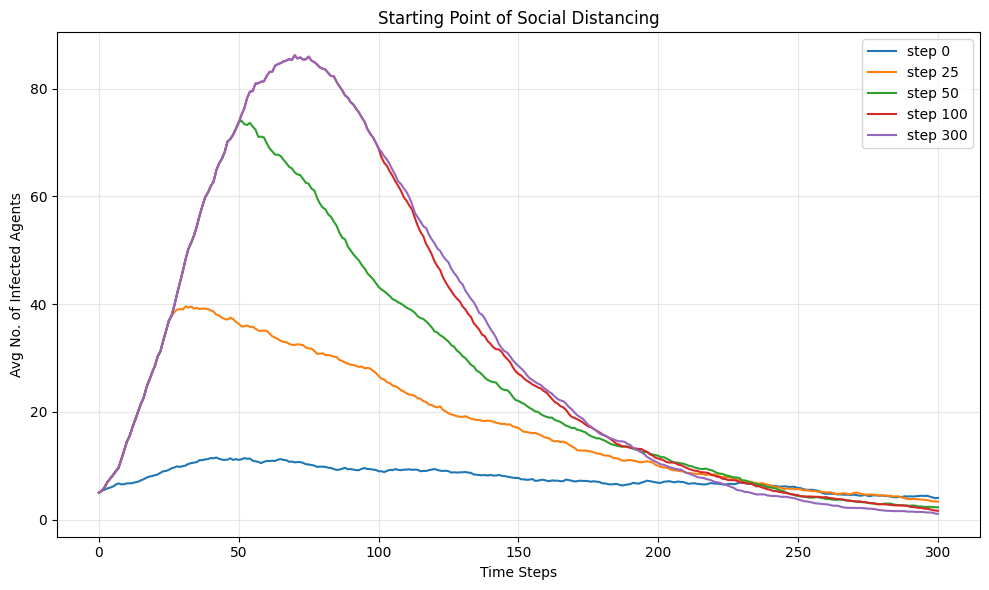

In [32]:
# Bonus(ii) -  Will the starting point of social distance make any impact?

def distancing(seed,startTime):
  agents = initialAgents(seed)
  randomGenerator = random.Random(seed+1000)
  totalInfectedCount = []

  for step in range(301):
    totalInfectedCount.append(sum(a["state"]=="I" for a in agents))
    if step < 300:
      m = 1.0 if step < startTime else 0.1
      simulationPartB(agents, 0.3, 0.02, randomGenerator, m)
  return numpy.array(totalInfectedCount)

startTimes = [0, 25, 50, 100, 300]
labels = ["step 0", "step 25", "step 50", "step 100", "step 300"]
plt.figure(figsize=(10,6))
for startTime, label in zip(startTimes, labels):
  runs = numpy.array([
      distancing(50+run, startTime)
      for run in range(20)  # lets take 20 runs each
  ])
  plt.plot(runs.mean(axis=0), label=label)
  print(label, "Avg Peak =", runs.max(axis=1).mean())

plt.xlabel("Time Steps")
plt.ylabel("Avg No. of Infected Agents")
plt.title("Starting Point of Social Distancing")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("partB_bonus.png")
plt.show()


My observation -
* As expeced, if we start social distance early, it will help in lowering infection peak and the graph showed exactly same.